# 12 — Persistent homology H₀/H₁ thật cho SBR

Vietoris–Rips filtration, boundary reduction trên F₂, Wasserstein diagram loss có gradient.
Đây là ứng viên nghiên cứu; chưa có bằng chứng PH cải thiện hơn cosine trong pilot.
Notebook 09–11 và checkpoint `*_topology` thuộc nhánh cosine legacy.

Cloud tham chiếu: target embedding trong batch TRAIN, chuẩn hóa L2, stop-gradient.
Cloud cần học: các session vector tương ứng. Rare anchors: `0 < train_frequency < 20`.
H₀ mô tả thành phần liên thông; H₁ mô tả vòng sinh–diệt khi thêm cạnh và tam giác.
Barcode dài không tự chứng minh một item có chất lượng hoặc phù hợp người dùng.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "BTL-K03-tong-quan-de-tai.md").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from btl_k03.topology import vietoris_rips_persistence, diagram_wasserstein_squared
print("Project:", ROOT)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

Project: D:\DA3-ThienlechdophobientrongkhonggianEmbedding
Device: cpu


## Kiểm tra vòng vuông

H₀ có ba bar hữu hạn chết ở 1 và một bar essential. H₁ sinh ở 1, chết ở √2:
hai đường chéo xuất hiện cùng các tam giác. Đây là PH của complex, không chỉ cycle graph.

In [2]:
square = torch.tensor([[0., 0.], [1., 0.], [1., 1.], [0., 1.]], requires_grad=True)
diagrams = vietoris_rips_persistence(square)
for dimension, diagram in diagrams.items():
    print(f"H{dimension}:", diagram.detach().numpy())
assert np.allclose(diagrams[1].detach().numpy(), [[1, np.sqrt(2)]])
(diagrams[1][:, 1] - diagrams[1][:, 0]).sum().backward()
assert torch.isfinite(square.grad).all() and square.grad.norm() > 0
print("Gradient qua cạnh sinh/diệt H1:", square.grad)

H0: [[ 0.  1.]
 [ 0.  1.]
 [ 0.  1.]
 [ 0. inf]]
H1: [[1.        1.4142135]]
Gradient qua cạnh sinh/diệt H1: tensor([[-0.7071, -0.7071],
        [ 0.0000,  0.0000],
        [-0.2929,  0.7071],
        [ 1.0000,  0.0000]])


## Chạy thí nghiệm

Đặt `RUN_TRAINING=True` khi muốn chạy. Mỗi lần chạy ghi thư mục mới; mặc định không đọc test.
Pilot giới hạn dữ liệu là smoke/pilot, không so trực tiếp với full-data baseline.
Để full training: đặt `FULL_DATA=True`, `EPOCHS=30`, tăng số seed, dùng GPU nếu có.
`--evaluate-test` chỉ dùng sau khi khóa thiết kế/config trên validation.
Các phương án: CE, dispersion-only, cosine, PH H₀, PH H₀+H₁.

In [3]:
import subprocess
RUN_TRAINING = False
FULL_DATA = False
EPOCHS = 2
if RUN_TRAINING:
    command = [sys.executable, "-B", str(ROOT / "scripts/train.py"),
               "--models", "gru4rec", "--methods", "baseline", "dispersion", "cosine", "ph_h0", "ph_h0_h1",
               "--seeds", "2024", "2025", "--epochs", str(EPOCHS),
               "--train-limit", "2048", "--validation-limit", "4096"]
    if FULL_DATA:
        command.append("--full-data")
    subprocess.run(command, cwd=ROOT, check=True)
else:
    print("Training chưa được bật; xem kết quả đã chạy bên dưới.")

Training chưa được bật; xem kết quả đã chạy bên dưới.


## Kết quả đo thật ngày 21/11/2026

GRU4Rec, fine-tune từ cùng checkpoint baseline trong từng seed, 2 epoch,
2.048 train examples và 4.096 validation examples mỗi seed. Checkpoint khởi đầu
đã dùng validation trước đó nên đây chỉ là phân tích thăm dò. Không đánh giá test.
Seed 2024 PH và cosine cùng thêm đúng một rare hit; seed 2025 không đổi rare hit.
H₁ loss khác 0 nhưng chưa tạo thêm Recall so với H₀. Cold/padding drift bằng 0.
CI bootstrap theo session là độ bất định trên mẫu đánh giá, không thay thế nhiều training seed.

In [4]:
PILOT = ROOT / "results/persistent_homology/pilot_20261121"
comparison = pd.read_csv(PILOT / "comparison.csv")
print(comparison.loc[comparison.target_group.isin(["all_warm", "rare"]),
      ["seed", "method", "target_group", "num_examples", "recall@20", "mrr@20", "frozen_drift"]].to_string(index=False))
assert comparison.frozen_drift.eq(0).all()
bootstrap = pd.read_csv(PILOT / "paired_session_bootstrap.csv")
print(bootstrap.loc[bootstrap.metric.eq("hit"), ["seed", "method", "target_group", "delta", "ci_low", "ci_high"]].to_string(index=False))

 seed   method target_group  num_examples  recall@20   mrr@20  frozen_drift
 2024 baseline     all_warm          4096   0.551025 0.192164           0.0
 2024 baseline         rare           260   0.326923 0.114420           0.0
 2024   cosine     all_warm          4096   0.551270 0.191929           0.0
 2024   cosine         rare           260   0.330769 0.114751           0.0
 2024    ph_h0     all_warm          4096   0.551514 0.192064           0.0
 2024    ph_h0         rare           260   0.330769 0.115125           0.0
 2024 ph_h0_h1     all_warm          4096   0.551514 0.192055           0.0
 2024 ph_h0_h1         rare           260   0.330769 0.115125           0.0
 2025 baseline     all_warm          4096   0.545654 0.186621           0.0
 2025 baseline         rare           237   0.333333 0.097835           0.0
 2025   cosine     all_warm          4096   0.545898 0.186811           0.0
 2025   cosine         rare           237   0.333333 0.098108           0.0
 2025    ph_

## Barcode và provenance

Ảnh và cặp birth/death thật đã xuất tại:
`results/persistent_homology/pilot_20261121/gru4rec/ph_h0_h1/seed_2024/persistence_diagrams/`.
Reference/trained dùng cùng neighbor ID, bỏ cold, ánh xạ chính xác embedding row = internal ID − 1.
Muốn xuất lại sang thư mục mới:

```powershell
python -B scripts/export_diagrams.py --run results/persistent_homology/pilot_20261121/gru4rec/ph_h0_h1/seed_2024 --reference-run runs/gru4rec/seed_2024 --output results/persistent_homology/diagrams_new
```

Nền tảng: [Topological Autoencoders (ICML 2020)](https://proceedings.mlr.press/v119/moor20a.html),
[A Topology Layer (AISTATS 2020)](https://proceedings.mlr.press/v108/gabrielsson20a.html).
Không tuyên bố phát minh PH hoặc xác nhận novelty tuyệt đối.

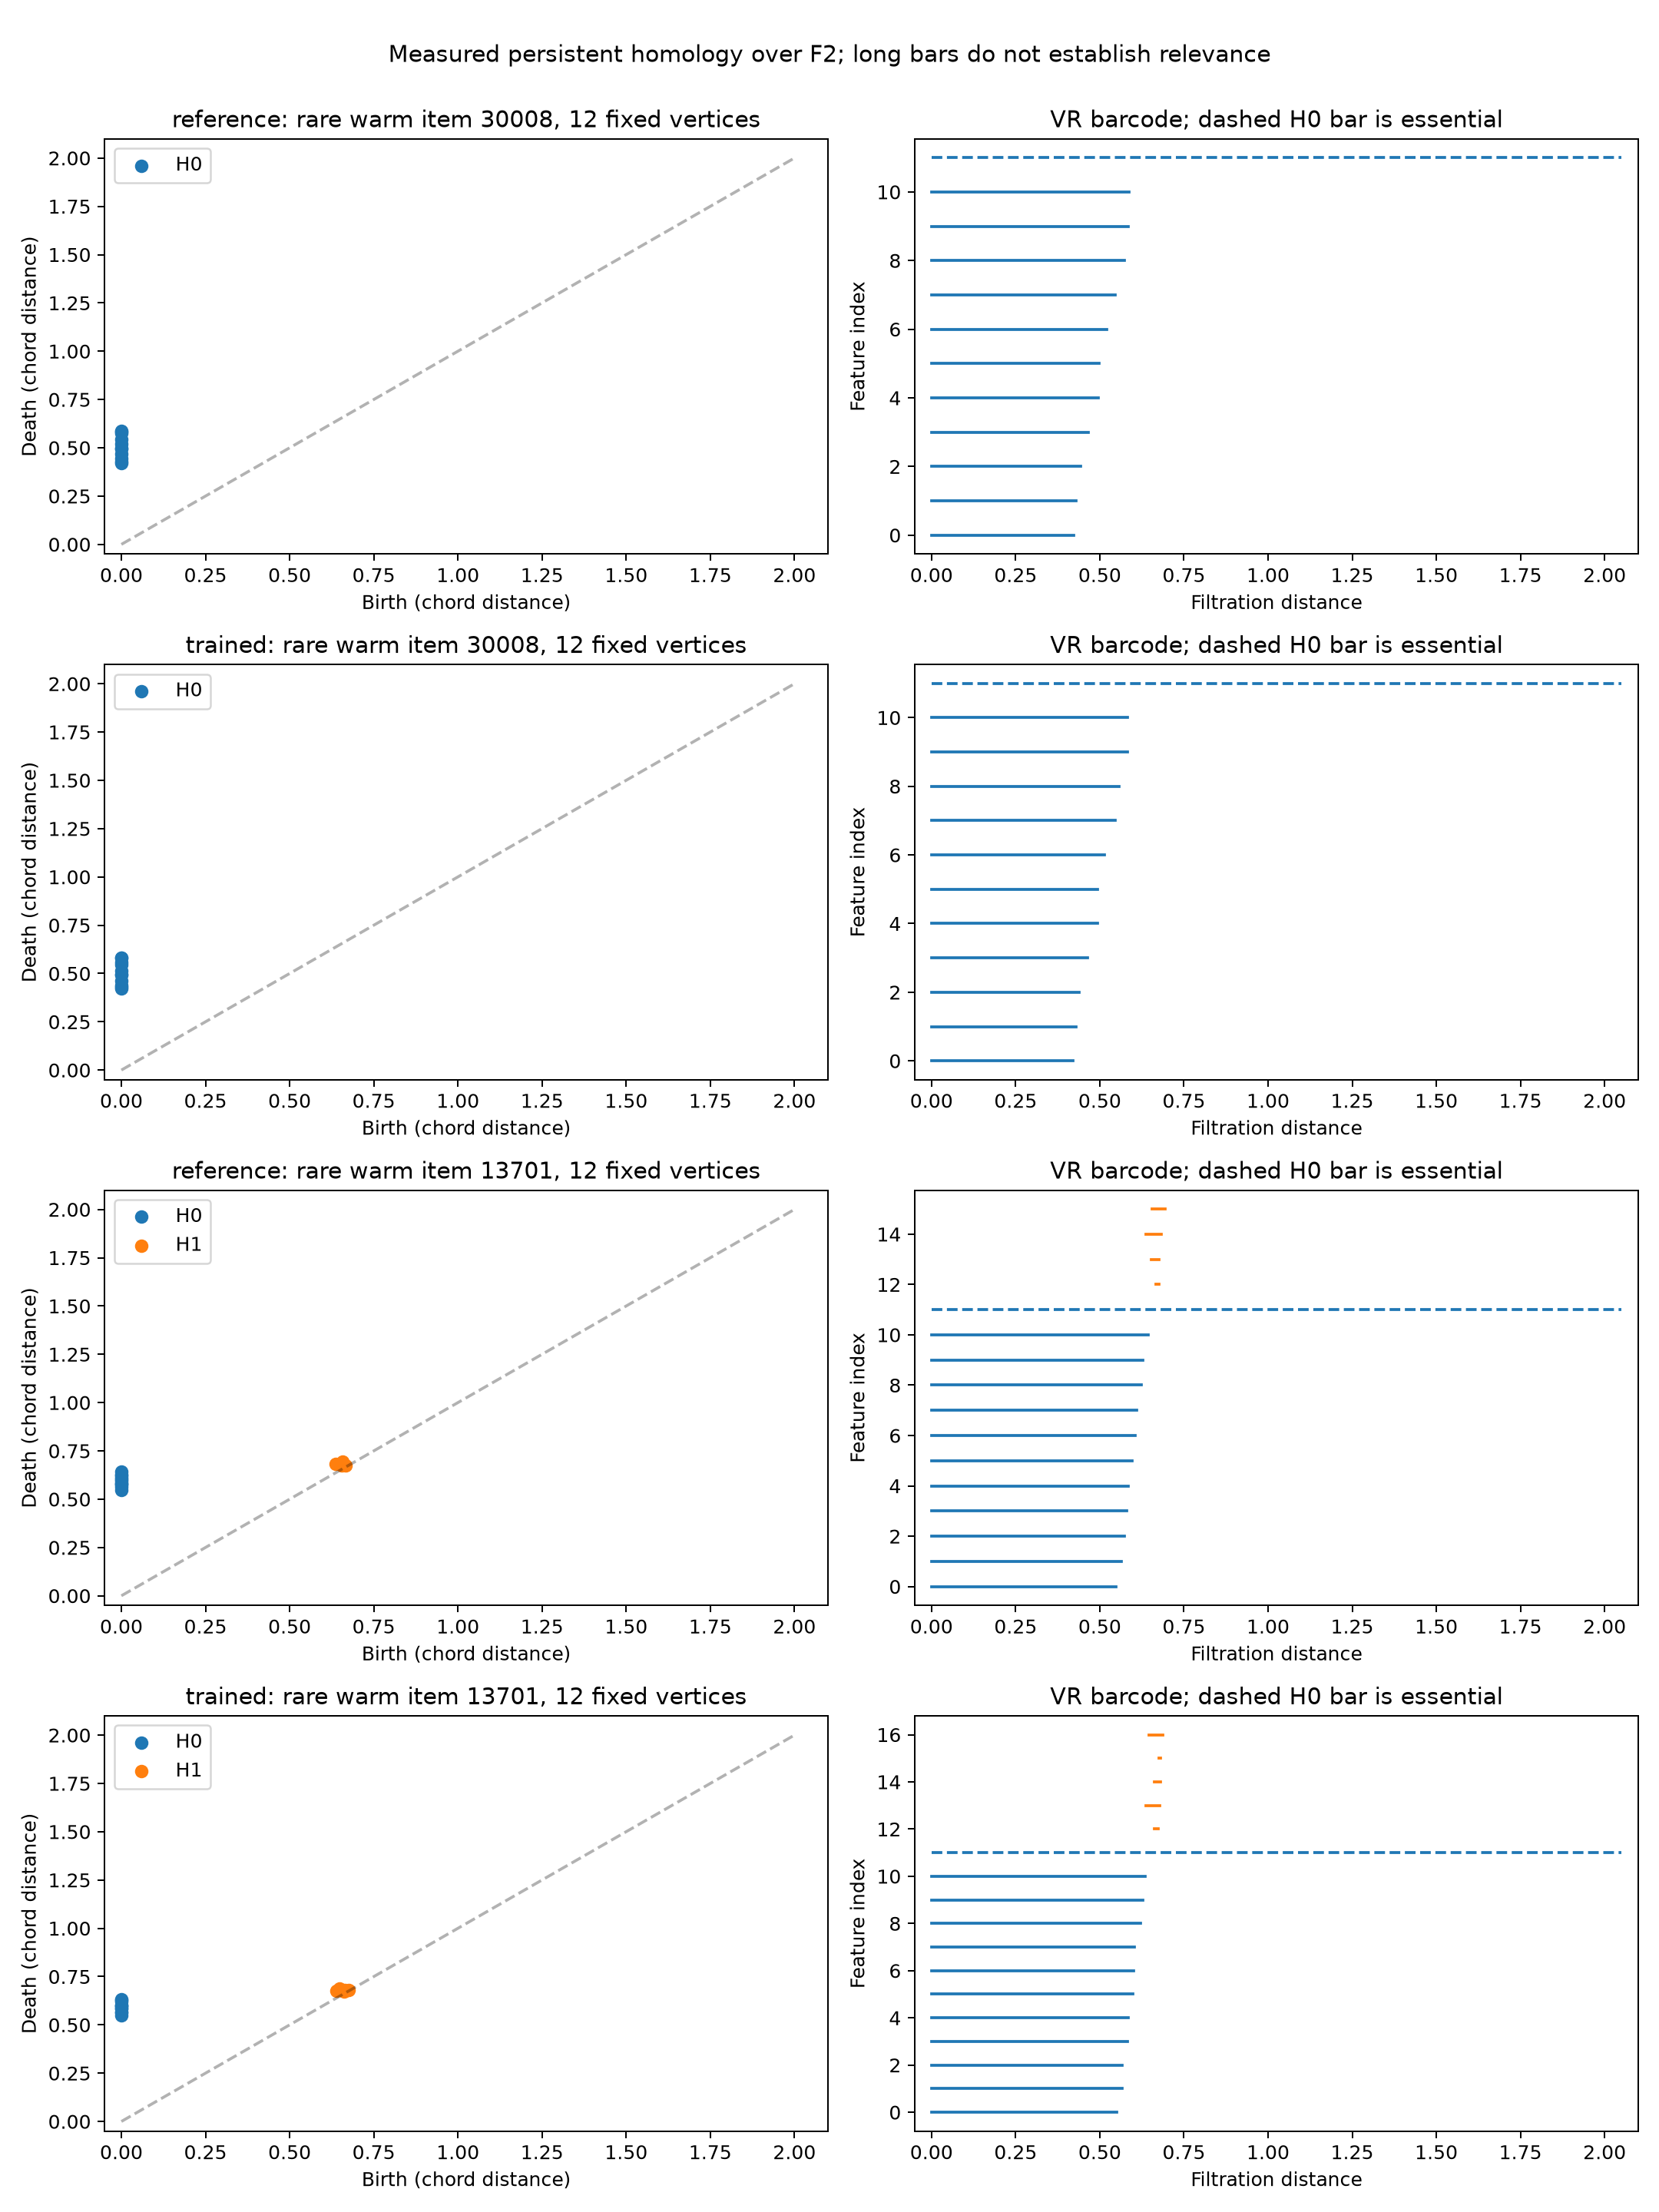

In [5]:
from IPython.display import Image, display
image_path = PILOT / "gru4rec/ph_h0_h1/seed_2024/persistence_diagrams/diagrams_and_barcodes.png"
display(Image(filename=str(image_path)))